Cell 1: setup and load

In [1]:
import os
import numpy as np
import pandas as pd
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

load_dotenv(find_dotenv())
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PG_USER"), password=os.getenv("PG_PASSWORD"),
    host=os.getenv("PG_HOST"), port=int(os.getenv("PG_PORT")),
    database=os.getenv("PG_DB"),
))

df = pd.read_sql("""
    SELECT f.*, l.target_capped_holdout
    FROM features.user_features f
    JOIN features.user_labels l USING (user_id)
""", engine)

TARGET = "target_capped_holdout"
FEATURES = [c for c in df.columns if c not in ("user_id", TARGET)]

# Leakage guard: fail loudly if a holdout-derived column sneaks in
banned = ("holdout", "z_holdout", "label_", "eval_set")
assert not any(b in c for c in FEATURES for b in banned), "Leakage: holdout-derived column in features"

print(df.shape, "| base rate:", round(df[TARGET].mean(), 3))
print(len(FEATURES), "features:", FEATURES)

(206209, 22) | base rate: 0.306
20 features: ['n_prior_orders', 'n_gaps', 'tenure_days_lb', 'mean_gap', 'median_gap', 'sd_gap', 'mean_gap_uncapped', 'n_capped_gaps', 'pct_capped_gaps', 'is_censored_heavy', 'n_same_day_gaps', 'last_prior_gap', 'recent_mean_gap', 'gap_trend', 'avg_basket_size', 'reorder_ratio', 'distinct_products', 'variety_ratio', 'avg_order_hour', 'is_truncated_history']


Cell 2: stratified split

In [2]:
train, test = train_test_split(
    df, test_size=0.2, stratify=df[TARGET], random_state=42
)
y_train, y_test = train[TARGET], test[TARGET]
print(len(train), len(test), round(y_train.mean(), 3), round(y_test.mean(), 3))

164967 41242 0.306 0.306


Cell 3: baseline scoring helper

In [4]:
def report(name, y_true, y_pred, y_score=None):
    out = {
        "model": name,
        "accuracy": (y_true == y_pred).mean(),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_score is not None:
        out["roc_auc"] = roc_auc_score(y_true, y_score)
        out["pr_auc"] = average_precision_score(y_true, y_score)
    return out

Cell 4: two baselines on the test set

In [5]:
results = []

# Baseline 1: always predict "not late"
results.append(report("majority (all 0)", y_test, np.zeros(len(y_test), dtype=int),
                      np.zeros(len(y_test))))

# Baseline 2: "predict capped if the last prior gap was capped"
naive_pred = (test["last_prior_gap"] == 30).astype(int)
results.append(report("naive: last gap capped", y_test, naive_pred, test["last_prior_gap"]))

pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,majority (all 0),0.694,0.000,0.000,0.000,0.500,0.306
1,naive: last gap capped,0.702,0.516,0.434,0.471,0.685,0.458


Cell 5: the confusion matrix of the naive rule

In [6]:
print(pd.DataFrame(confusion_matrix(y_test, naive_pred),
                   index=["actual on-time", "actual capped"],
                   columns=["pred on-time", "pred capped"]))

                pred on-time  pred capped
actual on-time         23447         5158
actual capped           7148         5489


Cell 6: pipeline

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

BOOL_COLS = ["is_censored_heavy", "is_truncated_history"]
DROP_FOR_LOGIT = ["n_gaps", "gap_trend"]          # exact linear combinations of other columns
LOGIT_FEATURES = [c for c in FEATURES if c not in DROP_FOR_LOGIT]
NUM_COLS = [c for c in LOGIT_FEATURES if c not in BOOL_COLS]

def to_model_frame(d):
    X = d[LOGIT_FEATURES].copy()
    X[BOOL_COLS] = X[BOOL_COLS].astype(int)
    return X

X_train, X_test = to_model_frame(train), to_model_frame(test)

prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), NUM_COLS),
    ("bool", "passthrough", BOOL_COLS),
])
logit = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
print(len(LOGIT_FEATURES), "features used")

18 features used


Cell 7: 5-fold cross-validation on the training set only

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(logit, X_train, y_train, cv=cv,
                        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                        n_jobs=-1)
for k in ("test_roc_auc", "test_pr_auc"):
    print(k, round(cv_res[k].mean(), 3), "+/-", round(cv_res[k].std(), 3))

test_roc_auc 0.758 +/- 0.003
test_pr_auc 0.537 +/- 0.006


Cell 8: fit, score the test set, compare fairly

In [9]:
logit.fit(X_train, y_train)
p_test = logit.predict_proba(X_test)[:, 1]

# Flag the same share of users as the naive rule, so precision/recall are comparable
flag_rate = naive_pred.mean()
thr = np.quantile(p_test, 1 - flag_rate)
pred_same_volume = (p_test >= thr).astype(int)

results.append(report(f"logistic (top {flag_rate:.1%} flagged)", y_test, pred_same_volume, p_test))
pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,majority (all 0),0.694,0.000,0.000,0.000,0.500,0.306
1,naive: last gap capped,0.702,0.516,0.434,0.471,0.685,0.458
2,logistic (top 25.8% flagged),0.720,0.550,0.464,0.503,0.754,0.537


Cell 9: what the model learned

In [10]:
names = logit.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logit.named_steps["clf"].coef_[0], index=names).sort_values()
print(coefs.round(3))

num__n_prior_orders                       -0.555
num__tenure_days_lb                       -0.295
bool__is_censored_heavy                   -0.215
num__avg_basket_size                      -0.140
num__median_gap                           -0.114
num__n_capped_gaps                        -0.108
bool__is_truncated_history                -0.052
num__variety_ratio                        -0.038
num__missingindicator_mean_gap_uncapped    0.008
num__avg_order_hour                        0.024
num__reorder_ratio                         0.037
num__n_same_day_gaps                       0.053
num__mean_gap_uncapped                     0.095
num__last_prior_gap                        0.140
num__distinct_products                     0.161
num__mean_gap                              0.184
num__sd_gap                                0.199
num__pct_capped_gaps                       0.208
num__recent_mean_gap                       0.460
dtype: float64


Cell 10: evidence of collinearity

In [11]:
gap_family = ["mean_gap", "median_gap", "recent_mean_gap", "last_prior_gap", "sd_gap", "pct_capped_gaps"]
train[gap_family].corr().round(2)

,mean_gap,median_gap,recent_mean_gap,last_prior_gap,sd_gap,pct_capped_gaps
mean_gap,1.00,0.96,0.87,0.65,0.12,0.86
median_gap,0.96,1.00,0.83,0.61,0.11,0.84
recent_mean_gap,0.87,0.83,1.00,0.77,0.12,0.75
last_prior_gap,0.65,0.61,0.77,1.00,0.11,0.56
sd_gap,0.12,0.11,0.12,0.11,1.00,0.07
pct_capped_gaps,0.86,0.84,0.75,0.56,0.07,1.00


Cell 11: model definition

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier

def to_tree_frame(d):
    X = d[FEATURES].copy()
    X[BOOL_COLS] = X[BOOL_COLS].astype(int)
    return X

Xt_train, Xt_test = to_tree_frame(train), to_tree_frame(test)

hgb = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=500,
    max_leaf_nodes=15,
    min_samples_leaf=100,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=42,
)
print(len(FEATURES), "features used")

20 features used


Cell 12: cross-validation

In [13]:
cv_hgb = cross_validate(hgb, Xt_train, y_train, cv=cv,
                        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                        n_jobs=1)
for k in ("test_roc_auc", "test_pr_auc"):
    print(k, round(cv_hgb[k].mean(), 3), "+/-", round(cv_hgb[k].std(), 3))

test_roc_auc 0.769 +/- 0.003
test_pr_auc 0.548 +/- 0.005


Cell 13: fit, score, compare at equal alert volume

In [14]:
hgb.fit(Xt_train, y_train)
print("trees used:", hgb.n_iter_)
p_hgb = hgb.predict_proba(Xt_test)[:, 1]

thr_h = np.quantile(p_hgb, 1 - flag_rate)
results.append(report(f"hist gradient boosting (top {flag_rate:.1%} flagged)",
                      y_test, (p_hgb >= thr_h).astype(int), p_hgb))
pd.DataFrame(results).round(3)

trees used: 225


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,majority (all 0),0.694,0.000,0.000,0.000,0.500,0.306
1,naive: last gap capped,0.702,0.516,0.434,0.471,0.685,0.458
2,logistic (top 25.8% flagged),0.720,0.550,0.464,0.503,0.754,0.537
3,hist gradient boosting (top 25.8% flagged),0.720,0.552,0.465,0.505,0.765,0.549


Cell 14: lift by decile (decile 1 = the 10% of users the model scores riskiest)

In [15]:
def decile_table(y, p, n=10):
    d = pd.DataFrame({"y": np.asarray(y), "p": p})
    d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), n, labels=range(1, n + 1))
    base = d["y"].mean()
    t = d.groupby("decile", observed=True).agg(
        users=("y", "size"), capped_rate=("y", "mean"), avg_pred=("p", "mean"))
    t["lift"] = t["capped_rate"] / base
    t["cum_capture"] = (t["capped_rate"] * t["users"]).cumsum() / d["y"].sum()
    return t.round(3)

print("Logistic"); display(decile_table(y_test, p_test))
print("Hist GB");  display(decile_table(y_test, p_hgb))

Logistic


,users,capped_rate,avg_pred,lift,cum_capture
decile,,,,,
1,4125,0.617,0.628,2.014,0.201
2,4124,0.530,0.550,1.729,0.374
3,4124,0.464,0.473,1.515,0.526
4,4124,0.389,0.394,1.271,0.653
5,4124,0.342,0.318,1.115,0.764
6,4124,0.267,0.249,0.872,0.852
7,4124,0.196,0.191,0.640,0.916
8,4124,0.147,0.142,0.479,0.964
9,4124,0.089,0.091,0.291,0.993


Hist GB


,users,capped_rate,avg_pred,lift,cum_capture
decile,,,,,
1,4125,0.624,0.620,2.035,0.204
2,4124,0.534,0.540,1.743,0.378
3,4124,0.462,0.479,1.507,0.528
4,4124,0.408,0.415,1.333,0.662
5,4124,0.338,0.344,1.102,0.772
6,4124,0.271,0.271,0.885,0.860
7,4124,0.219,0.200,0.716,0.932
8,4124,0.143,0.131,0.468,0.979
9,4124,0.063,0.068,0.205,0.999


Cell 15: calibration (are the probabilities honest?)

Brier of always predicting the base rate: 0.213


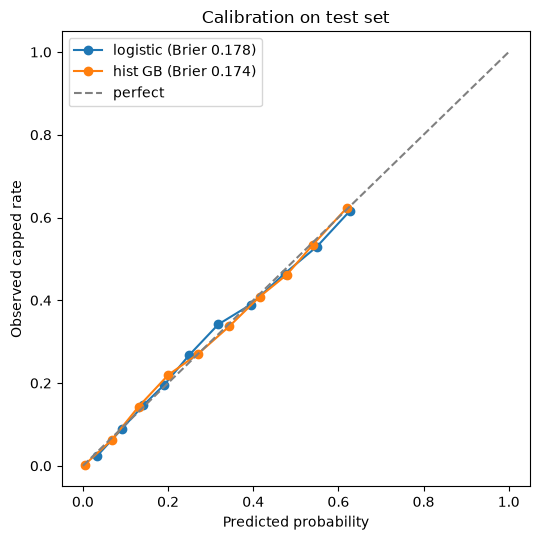

In [16]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for name, p in [("logistic", p_test), ("hist GB", p_hgb)]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=f"{name} (Brier {brier_score_loss(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed capped rate")
ax.set_title("Calibration on test set"); ax.legend()
plt.tight_layout(); plt.savefig("../docs/calibration.png", dpi=120)

base = y_test.mean()
print("Brier of always predicting the base rate:", round(base * (1 - base), 3))

Cell 16: what a contact budget buys

In [17]:
yv = np.asarray(y_test)
rows = []
for name, p in [("logistic", p_test), ("hist GB", p_hgb)]:
    for share in [0.05, 0.10, 0.20, 0.30]:
        flag = p >= np.quantile(p, 1 - share)
        rows.append(dict(model=name, contact_share=share,
                         precision=yv[flag].mean(),
                         recall=yv[flag].sum() / yv.sum(),
                         lift=yv[flag].mean() / yv.mean()))
pd.DataFrame(rows).round(3)

,model,contact_share,precision,recall,lift
0,logistic,0.05,0.643,0.105,2.098
1,logistic,0.10,0.617,0.201,2.014
2,logistic,0.20,0.573,0.374,1.871
3,logistic,0.30,0.537,0.526,1.753
4,hist GB,0.05,0.666,0.109,2.174
5,hist GB,0.10,0.624,0.204,2.035
6,hist GB,0.20,0.579,0.378,1.889
7,hist GB,0.30,0.540,0.528,1.761


Cell 17: permutation importance, single features

In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(hgb, Xt_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=42, n_jobs=1)
imp = pd.DataFrame({"feature": Xt_test.columns,
                    "pr_auc_drop": perm.importances_mean,
                    "sd": perm.importances_std}).sort_values("pr_auc_drop", ascending=False)
imp.round(4)

,feature,pr_auc_drop,sd
12,recent_mean_gap,0.0803,0.0033
2,tenure_days_lb,0.0393,0.0010
0,n_prior_orders,0.0153,0.0014
11,last_prior_gap,0.0135,0.0011
16,distinct_products,0.0064,0.0008
7,n_capped_gaps,0.0038,0.0010
15,reorder_ratio,0.0035,0.0004
8,pct_capped_gaps,0.0017,0.0002
6,mean_gap_uncapped,0.0017,0.0004
4,median_gap,0.0013,0.0003


Cell 18: grouped permutation importance (the fix)

In [19]:
groups = {
    "recent/typical gap": ["mean_gap", "median_gap", "recent_mean_gap", "last_prior_gap",
                           "mean_gap_uncapped", "gap_trend"],
    "capping / variability": ["n_capped_gaps", "pct_capped_gaps", "is_censored_heavy",
                              "sd_gap", "n_same_day_gaps"],
    "tenure": ["n_prior_orders", "n_gaps", "tenure_days_lb", "is_truncated_history"],
    "basket": ["avg_basket_size", "reorder_ratio", "distinct_products", "variety_ratio"],
    "time of day": ["avg_order_hour"],
}
assert sorted(sum(groups.values(), [])) == sorted(FEATURES), "groups must cover every feature once"

rng = np.random.default_rng(42)
base_pr, base_roc = average_precision_score(y_test, p_hgb), roc_auc_score(y_test, p_hgb)
rows = []
for name, cols in groups.items():
    d_pr, d_roc = [], []
    for _ in range(5):
        Xp = Xt_test.copy()
        idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].iloc[idx].to_numpy()   # shuffle the whole group together
        pp = hgb.predict_proba(Xp)[:, 1]
        d_pr.append(base_pr - average_precision_score(y_test, pp))
        d_roc.append(base_roc - roc_auc_score(y_test, pp))
    rows.append(dict(group=name, n_features=len(cols),
                     pr_auc_drop=np.mean(d_pr), roc_auc_drop=np.mean(d_roc)))
pd.DataFrame(rows).sort_values("pr_auc_drop", ascending=False).round(4)

,group,n_features,pr_auc_drop,roc_auc_drop
0,recent/typical gap,6,0.1540,0.1331
2,tenure,4,0.0662,0.0893
3,basket,4,0.0144,0.0055
1,capping / variability,5,0.0080,0.0091
4,time of day,1,-0.0004,0.0000


Cell 19: partial dependence (the shape of the effect)

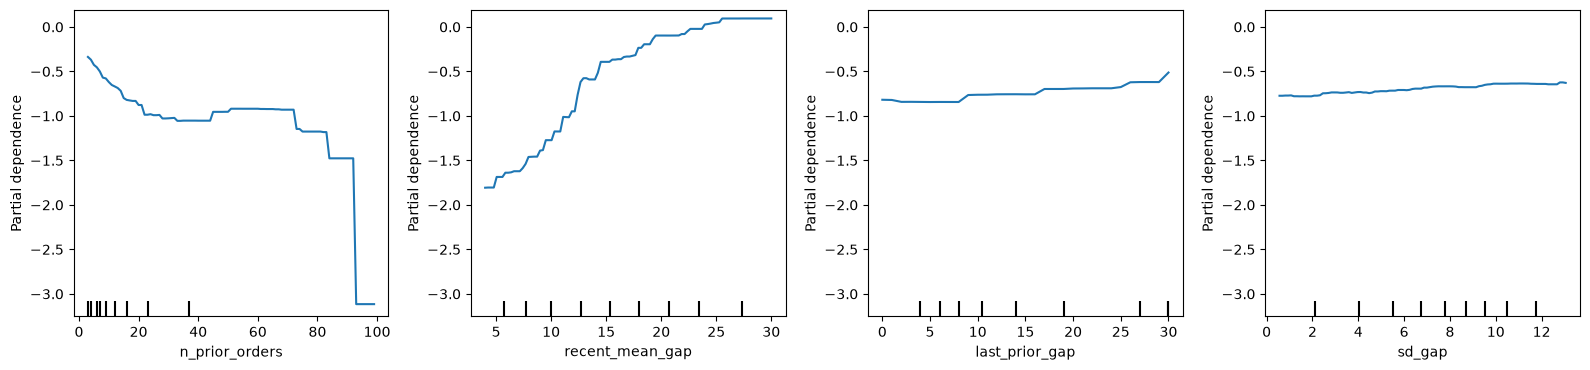

In [21]:
from sklearn.inspection import PartialDependenceDisplay

sample = Xt_test.sample(8000, random_state=42).astype(float)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(
    hgb, sample, ["n_prior_orders", "recent_mean_gap", "last_prior_gap", "sd_gap"],
    ax=ax, kind="average")
plt.tight_layout()
plt.savefig("../docs/partial_dependence.png", dpi=120)